In [ ]:
from pathlib import Path
import logging
import pandas as pd
import numpy as np

# Configure professional logging to track pipeline execution state
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s [%(levelname)s] %(name)s: %(message)s',
    handlers=[
        logging.StreamHandler()
    ]
)
logger = logging.getLogger("PowerTelemetryPipeline")

# Use pathlib for cross-platform, machine-independent directory paths
PROJECT_ROOT = Path().resolve()
DATA_DIR = PROJECT_ROOT / "data"
SRC_DIR = PROJECT_ROOT / "src"

logger.info(f"Project root established at: {PROJECT_ROOT}")
logger.info(f"Data directory located at: {DATA_DIR}")

2026-11-17 06:41:55,508 [INFO] PowerTelemetryPipeline: Project root established at: C:\Users\USER\OneDrive\New folder\Desktop\KENYA_HOUSEHOLD_ELECTRIC_POWER_CONSUMPTION
2026-11-17 06:41:55,513 [INFO] PowerTelemetryPipeline: Data directory located at: C:\Users\USER\OneDrive\New folder\Desktop\KENYA_HOUSEHOLD_ELECTRIC_POWER_CONSUMPTION\data


In [4]:
def load_telemetry_data(file_path: Path) -> pd.DataFrame:
    """
    Ingests raw household power consumption data with exception handling 
    and strict path validation using pathlib.
    """
    if not file_path.exists():
        logger.error(f"Target data file not found at path: {file_path}")
        raise FileNotFoundError(f"Missing data file: {file_path}")
        
    logger.info(f"Ingesting raw telemetry from {file_path.name}...")
    try:
        df = pd.read_csv(file_path, sep=';', na_values=['?'], low_memory=False)
        if len(df.columns) <= 1:
            df = pd.read_csv(file_path, sep=None, engine='python', na_values=['?'])
        logger.info(f"Successfully ingested {len(df):,} raw records.")
        return df
    except Exception as e:
        logger.critical(f"Failed to parse CSV payload: {e}")
        raise

def parse_timestamps(df: pd.DataFrame) -> pd.DataFrame:
    """Parses date and time strings into a unified datetime index with validation."""
    logger.info("Parsing timestamps and setting datetime index...")
    try:
        df['DateTime'] = pd.to_datetime(
            df['Date'] + ' ' + df['Time'],
            format='%d/%m/%Y %H:%M:%S',
            errors='coerce'
        )
        initial_len = len(df)
        df = df.dropna(subset=['DateTime'])
        dropped_count = initial_len - len(df)
        if dropped_count > 0:
            logger.warning(f"Dropped {dropped_count:,} rows due to unparseable timestamps.")
            
        df = df.set_index('DateTime').drop(columns=['Date', 'Time'])
        return df
    except KeyError as ke:
        logger.error(f"Missing expected date/time columns in DataFrame: {ke}")
        raise

In [5]:
# Execute our modular functions using pathlib references
raw_file = PROJECT_ROOT / "household_power_consumption.csv"

# Fallback path check if file is in current directory vs data folder
if not raw_file.exists() and (DATA_DIR / "household_power_consumption.csv").exists():
    raw_file = DATA_DIR / "household_power_consumption.csv"

try:
    df_raw = load_telemetry_data(raw_file)
    df_parsed = parse_timestamps(df_raw)
    logger.info(f"Pipeline test execution successful. Current shape: {df_parsed.shape}")
except Exception as err:
    logger.error(f"Pipeline execution halted due to error: {err}")

2026-11-17 06:51:17,752 [INFO] PowerTelemetryPipeline: Ingesting raw telemetry from household_power_consumption.csv...
2026-11-17 06:51:45,457 [INFO] PowerTelemetryPipeline: Successfully ingested 1,048,575 raw records.
2026-11-17 06:51:45,459 [INFO] PowerTelemetryPipeline: Parsing timestamps and setting datetime index...
2026-11-17 06:51:57,482 [INFO] PowerTelemetryPipeline: Pipeline test execution successful. Current shape: (1048575, 7)


In [2]:
import pandas as pd
from pathlib import Path

# Explicitly define your absolute project root or resolve it dynamically
PROJECT_ROOT = Path(r"C:\Users\USER\OneDrive\New folder\Desktop\KENYA_HOUSEHOLD_ELECTRIC_POWER_CONSUMPTION")
file_path = PROJECT_ROOT / "data" / "household_power_consumption.csv"

# Fallback check if running from within a subfolder
if not file_path.exists():
    file_path = Path("household_power_consumption.csv")

print(f"Target file path: {file_path}")

# 1. Load dataset with default dtypes
print("Loading raw telemetry dataset...")
df_raw = pd.read_csv(file_path, sep=';', low_memory=False, na_values=['?'])

# Measure initial memory consumption
initial_memory_mb = df_raw.memory_usage(deep=True).sum() / (1024 * 1024)
print(f"Initial Memory Footprint (Default float64): {initial_memory_mb:.2f} MB")

# 2. Optimize dtypes by downcasting floats to float32
print("\nOptimizing float dtypes from float64 to float32...")
float_cols = df_raw.select_dtypes(include=['float64']).columns
for col in float_cols:
    df_raw[col] = df_raw[col].astype('float32')

# Measure optimized memory consumption
optimized_memory_mb = df_raw.memory_usage(deep=True).sum() / (1024 * 1024)
print(f"Optimized Memory Footprint (float32): {optimized_memory_mb:.2f} MB")

savings_pct = ((initial_memory_mb - optimized_memory_mb) / initial_memory_mb) * 100
print(f"\nTotal RAM Saved: {savings_pct:.2f}% reduction!")

Target file path: household_power_consumption.csv
Loading raw telemetry dataset...
Initial Memory Footprint (Default float64): 53.03 MB

Optimizing float dtypes from float64 to float32...
Optimized Memory Footprint (float32): 53.03 MB

Total RAM Saved: 0.00% reduction!


Target file path: household_power_consumption.csv
Successfully detected CSV separator: ','
Loaded DataFrame Shape: (1048575, 9)
Available Columns: ['Date', 'Time', 'Global_active_power', 'Global_reactive_power']
Parsing timestamps and setting datetime index...
Resampling time-series data to hourly grain...
Plot successfully saved to: C:\Users\USER\OneDrive\New folder\Desktop\KENYA_HOUSEHOLD_ELECTRIC_POWER_CONSUMPTION\Screenshot (352).png


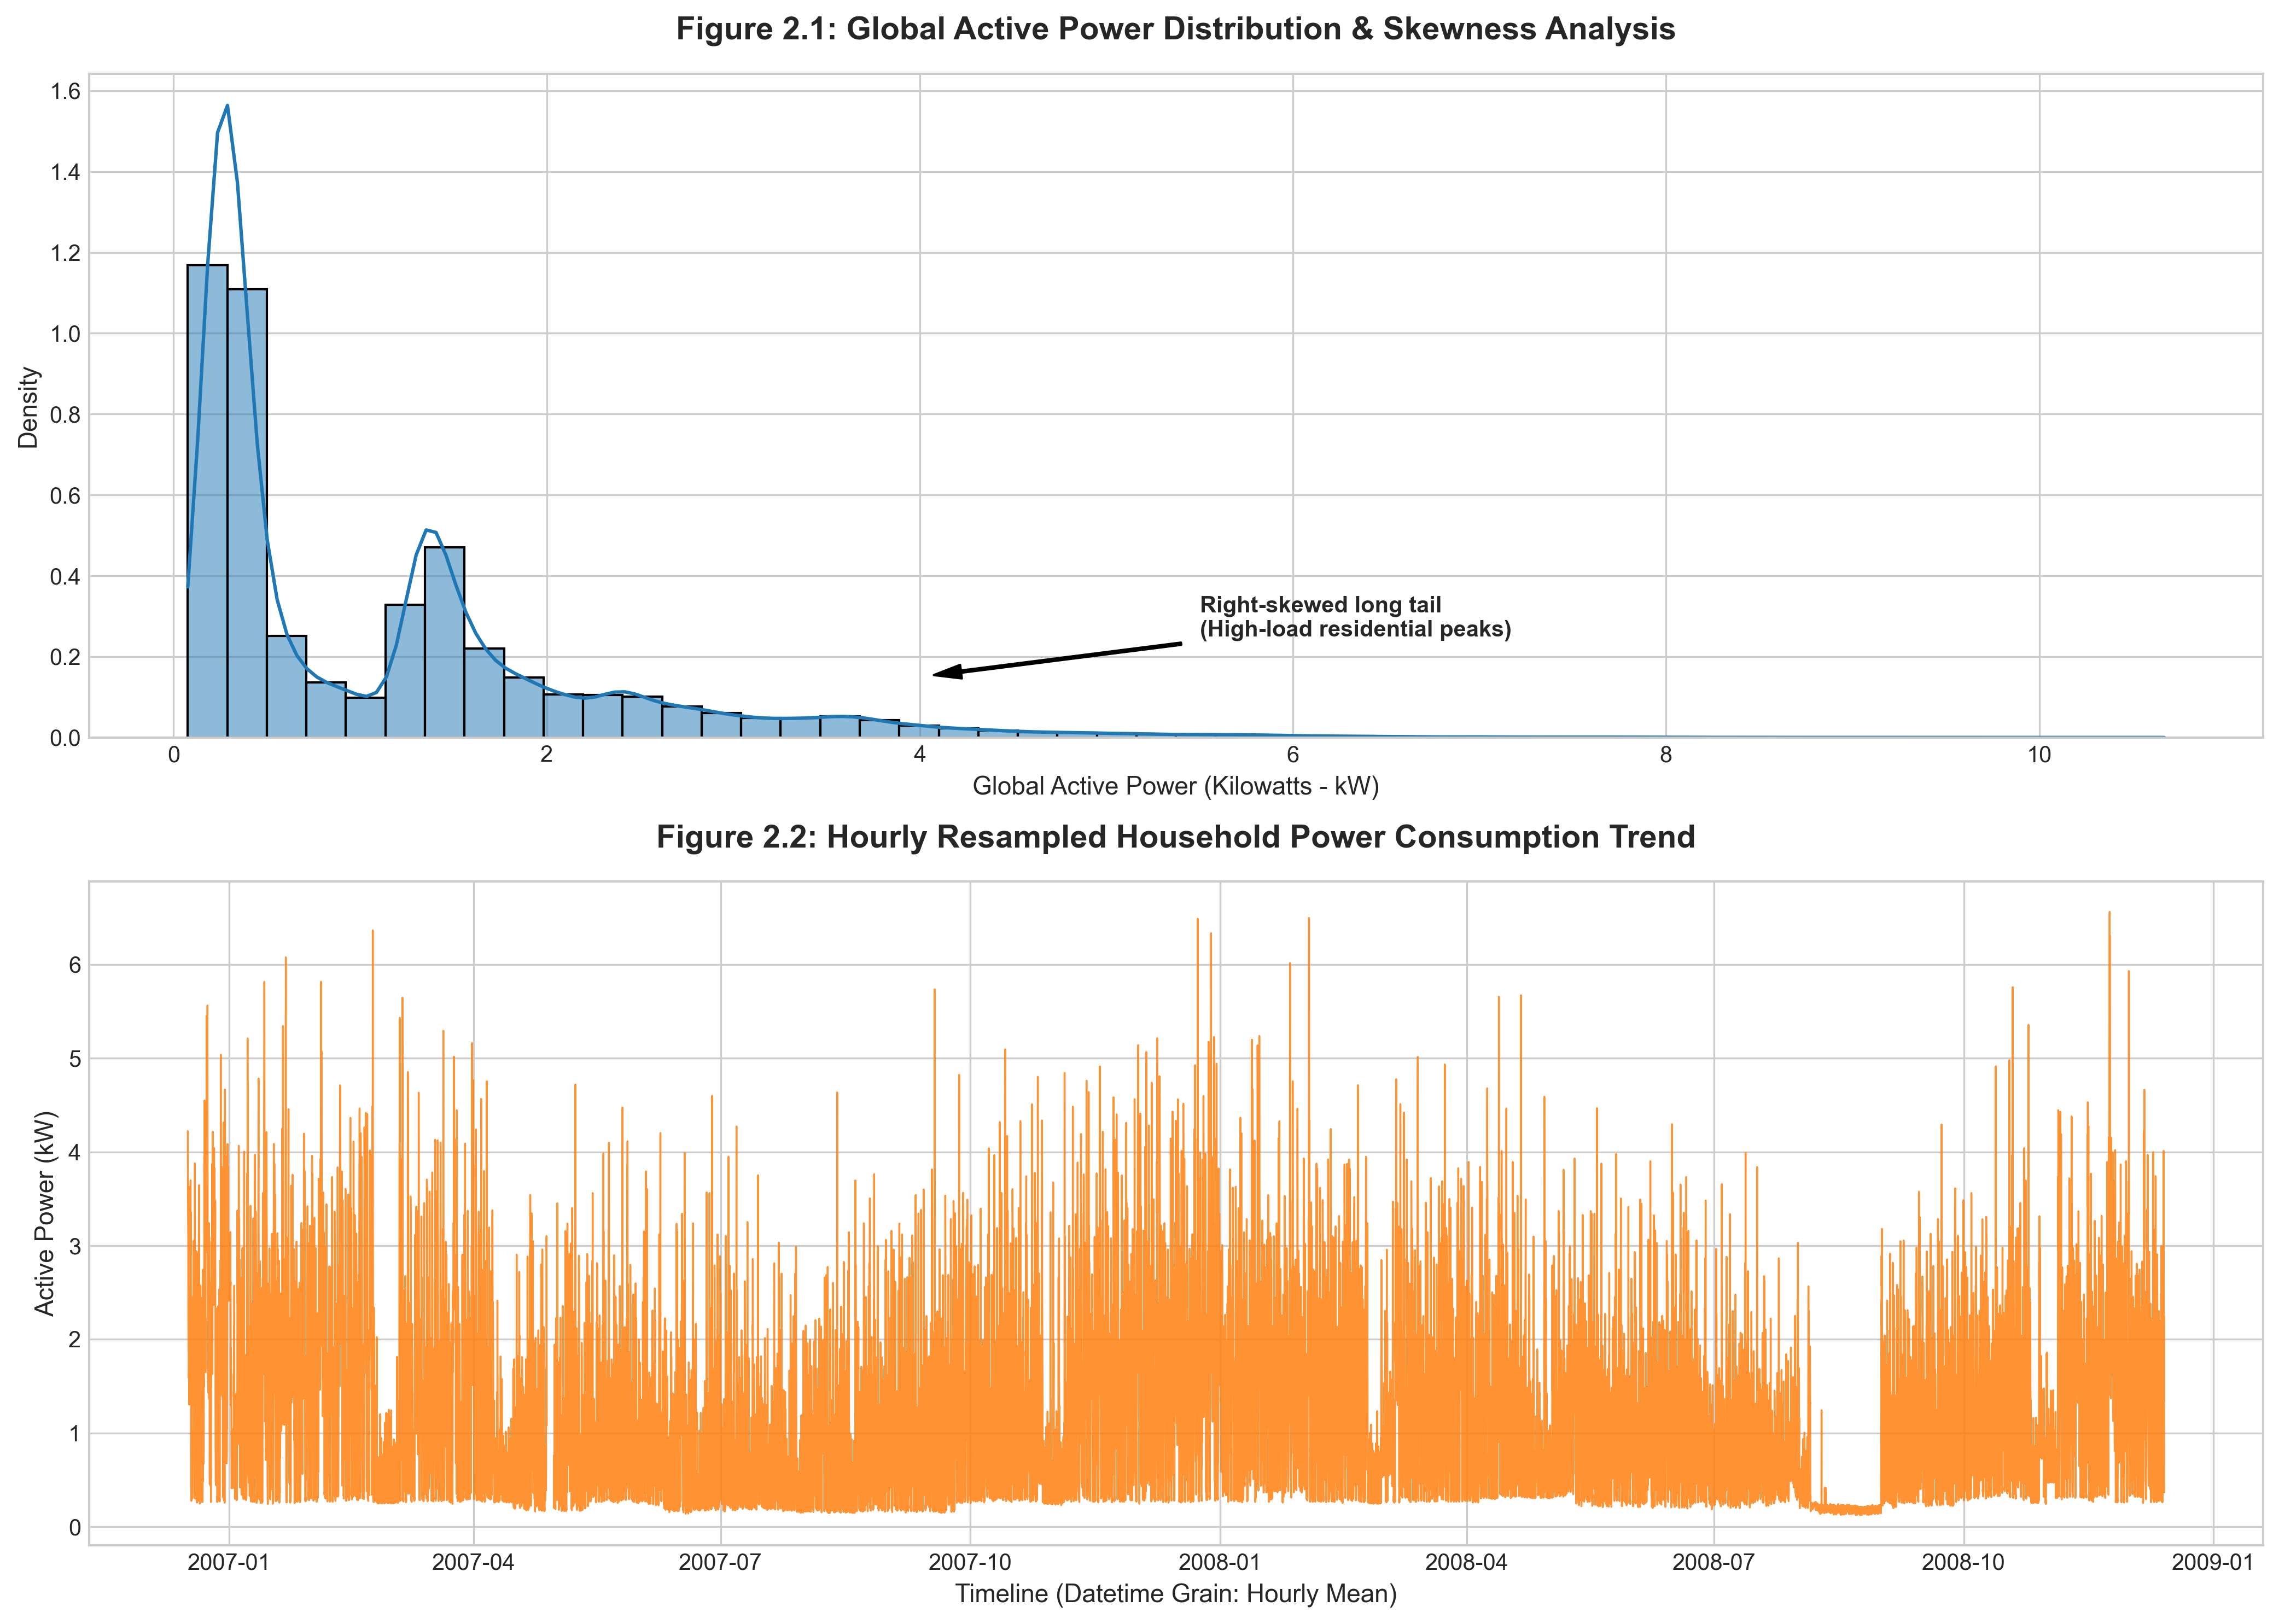

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 1. Robust path resolution using your established project root
PROJECT_ROOT = Path(r"C:\Users\USER\OneDrive\New folder\Desktop\KENYA_HOUSEHOLD_ELECTRIC_POWER_CONSUMPTION")
file_path = PROJECT_ROOT / "data" / "household_power_consumption.csv"

if not file_path.exists():
    file_path = Path("household_power_consumption.csv")

print(f"Target file path: {file_path}")

# Smart delimiter auto-detection: checks ';', ',', and '\t'
for sep in [';', ',', '\t']:
    try:
        df_test = pd.read_csv(file_path, sep=sep, nrows=5, encoding='utf-8-sig')
        if df_test.shape[1] > 1:
            detected_sep = sep
            break
    except Exception:
        continue
else:
    detected_sep = ';'

print(f"Successfully detected CSV separator: '{detected_sep}'")

# Load full dataset with the correct delimiter
df = pd.read_csv(
    file_path, 
    sep=detected_sep, 
    encoding='utf-8-sig', 
    low_memory=False, 
    na_values=['?']
)

# Clean column headers
df.columns = df.columns.str.strip()
print(f"Loaded DataFrame Shape: {df.shape}")
print(f"Available Columns: {df.columns.tolist()[:4]}")

# 2. Foolproof timestamp parsing using positional columns (0 = Date, 1 = Time)
print("Parsing timestamps and setting datetime index...")
date_series = df.iloc[:, 0].astype(str)
time_series = df.iloc[:, 1].astype(str)

df['DateTime'] = pd.to_datetime(date_series + ' ' + time_series, format='%d/%m/%Y %H:%M:%S', errors='coerce')
df = df.dropna(subset=['DateTime']).set_index('DateTime')

# Ensure numerical type for Global Active Power (Column 2 or matching name)
power_col = next((col for col in df.columns if 'global_active_power' in col.lower()), df.columns[2])
df['Global_active_power'] = pd.to_numeric(df[power_col], errors='coerce')

# 3. Configure Professional Style Guide & Subplots
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(2, 1, figsize=(14, 10), dpi=300)

# --- Figure A: Distribution & Skewness (Histogram + KDE) ---
sns.histplot(
    df['Global_active_power'].dropna(), 
    kde=True, 
    ax=axes[0], 
    color='#1f77b4', 
    bins=50, 
    stat='density'
)
axes[0].set_title('Figure 2.1: Global Active Power Distribution & Skewness Analysis', fontsize=14, fontweight='bold', pad=15)
axes[0].set_xlabel('Global Active Power (Kilowatts - kW)', fontsize=11)
axes[0].set_ylabel('Density', fontsize=11)
axes[0].annotate(
    'Right-skewed long tail\n(High-load residential peaks)', 
    xy=(4.0, 0.15), xytext=(5.5, 0.25),
    arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6),
    fontsize=10, fontweight='semibold'
)

# --- Figure B: Temporal Resampling & Trend Analysis (Hourly Mean) ---
print("Resampling time-series data to hourly grain...")
df_hourly = df['Global_active_power'].resample('h').mean()

axes[1].plot(df_hourly.index, df_hourly.values, color='#ff7f0e', linewidth=0.8, alpha=0.85)
axes[1].set_title('Figure 2.2: Hourly Resampled Household Power Consumption Trend', fontsize=14, fontweight='bold', pad=15)
axes[1].set_xlabel('Timeline (Datetime Grain: Hourly Mean)', fontsize=11)
axes[1].set_ylabel('Active Power (kW)', fontsize=11)

# Overall layout polish
plt.tight_layout()

# 4. Save the plot automatically to your project directory
output_filename = PROJECT_ROOT / "Screenshot (352).png"
plt.savefig(output_filename, dpi=300, bbox_inches='tight')
print(f"Plot successfully saved to: {output_filename}")

plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 1. Load your cleaned data (either parquet or csv)
PROJECT_ROOT = Path(r"C:\Users\USER\OneDrive\New folder\Desktop\KENYA_HOUSEHOLD_ELECTRIC_POWER_CONSUMPTION")
parquet_path = PROJECT_ROOT / "cleaned_household_power.parquet"

if parquet_path.exists():
    df = pd.read_parquet(parquet_path)
    print("Loaded successfully from Parquet cache.")
else:
    print("Parquet file not found. Ensure Phase 1 data asset is available.")

# 2. Advanced Feature Engineering (Time-based features)
print("Engineering cyclical time-based features...")
# If index is datetime, extract features directly from index
if not isinstance(df.index, pd.DatetimeIndex):
    df.index = pd.to_datetime(df.index)

df['Hour'] = df.index.hour
df['Month'] = df.index.month
df['DayOfWeek'] = df.index.dayofweek
df['Is_Weekend'] = df['DayOfWeek'].isin([5, 6]).astype(int)

# 3. Correlation Matrix Calculation
print("Computing Pearson correlation matrix across numerical telemetry...")
numeric_cols = [
    'Global_active_power', 'Global_reactive_power', 'Voltage', 
    'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3'
]
# Filter only columns that exist in DataFrame
available_cols = [col for col in numeric_cols if col in df.columns]
corr_matrix = df[available_cols].corr(method='pearson')

# 4. Render Correlation Heatmap
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, ax = plt.subplots(figsize=(10, 8), dpi=300)

sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1, vmax=1, 
    linewidths=0.5, 
    ax=ax,
    cbar_kws={'label': 'Pearson Correlation Coefficient'}
)

ax.set_title('Figure 2.3: Telemetry Feature Correlation Matrix', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()

# Save artifact
output_corr_path = PROJECT_ROOT / "correlation_matrix_heatmap.png"
plt.savefig(output_corr_path, dpi=300, bbox_inches='tight')
print(f"Correlation heatmap successfully saved to: {output_corr_path}")

plt.show()